# Chapitre 4 - Cours 6 : Embeddings et index vectoriels

Ce notebook couvre la sous-section *Vector Embeddings* de la section
*Multidimensional and Full-Text Indexes*, nouvelle dans la 2e édition : la recherche
sémantique, les embeddings, les distances cosinus et euclidienne, et les trois familles
d'index vectoriels citées par le livre (plat, IVF, HNSW). Le livre renvoie aux articles
pour le détail des algorithmes : nous les implémentons (`ddia/storage_vectors.py`) et
mesurons le compromis rappel / coût.

**Plan.**

1. De la recherche plein texte à la recherche sémantique.
2. Mesurer la proximité : cosinus et distance euclidienne.
3. L'index plat : exact mais linéaire.
4. L'index IVF : partitionner l'espace, sonder quelques partitions.
5. L'index HNSW : un graphe de proximité à plusieurs couches.
6. Pourquoi pas un R-tree ? La malédiction de la dimension.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import storage_vectors as V
from ddia import storage as S
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)

## 1. De la recherche plein texte à la recherche sémantique (section *Vector Embeddings*)

La recherche plein texte trouve les documents qui contiennent **les mots** de la
requête (cours 4), avec un peu de tolérance aux fautes. La **recherche sémantique** vise
le **sens** : une page d'aide intitulée « résilier son abonnement » doit sortir pour la
requête « comment fermer mon compte », sans aucun mot commun. C'est une brique des
applications d'IA, par exemple la génération augmentée par la recherche (RAG), qui
injecte des documents trouvés dans la réponse d'un grand modèle de langage.

**L'embedding.** Un **modèle d'embedding** (souvent un réseau de neurones, parfois un
LLM) transforme un document en un **vecteur de nombres flottants**, un point dans un
espace à plusieurs centaines ou milliers de dimensions. Le modèle est entraîné pour que
des documents **proches par le sens** donnent des **points proches**. On ne cherche pas
à interpréter chaque coordonnée. Les premiers modèles travaillaient sur du texte
(Word2Vec, BERT, GPT) ; il en existe pour les images, le son, la vidéo, et des modèles
**multimodaux** qui placent texte et images dans le même espace.

Attention au faux ami : le **traitement vectorisé** du cours 5 désigne des lots de
valeurs traités par des instructions spécialisées ; ici, un **vecteur** est un point de
l'espace.

Un exemple jouet en trois dimensions (valeurs inventées pour l'illustration) :

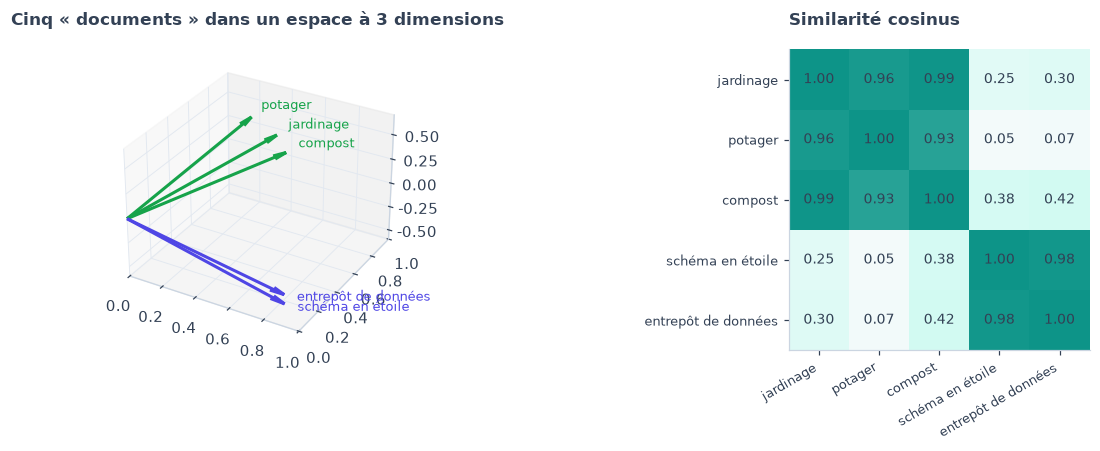

In [2]:
jouet = pd.DataFrame({
    "jardinage": [0.42, 0.80, 0.39], "potager": [0.33, 0.69, 0.62], "compost": [0.51, 0.74, 0.30],
    "schéma en étoile": [0.88, 0.07, -0.46], "entrepôt de données": [0.80, 0.21, -0.55],
}, index=["x", "y", "z"]).T
sims = pd.DataFrame({a: {b: V.cosine_similarity(jouet.loc[a], jouet.loc[b]) for b in jouet.index}
                     for a in jouet.index})
fig = plt.figure(figsize=(12, 4.2))
ax = fig.add_subplot(1, 2, 1, projection="3d")
for nom, c in zip(jouet.index, [GREEN, GREEN, GREEN, INDIGO, INDIGO]):
    v = jouet.loc[nom].to_numpy()
    ax.quiver(0, 0, 0, *v, color=c, arrow_length_ratio=0.08, lw=2)
    ax.text(*(v * 1.08), nom, fontsize=8.5, color=c)
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_zlim(-0.6, 0.7)
ax.set_title("Cinq « documents » dans un espace à 3 dimensions", fontsize=11)
ax2 = fig.add_subplot(1, 2, 2)
ax2.imshow(sims.values, cmap="ddia_div", vmin=-1, vmax=1)
for i in range(len(sims)):
    for j in range(len(sims)):
        ax2.text(j, i, f"{sims.values[i, j]:.2f}", ha="center", va="center", fontsize=9, color=SLATE)
ax2.set_xticks(range(len(sims)), sims.columns, rotation=30, ha="right", fontsize=8.5)
ax2.set_yticks(range(len(sims)), sims.index, fontsize=8.5)
ax2.grid(False)
ax2.set_title("Similarité cosinus", fontsize=11)
plt.tight_layout(); plt.show()

Les trois documents de jardinage forment un groupe (similarités supérieures à 0,9), les
deux documents sur l'analytique un autre ; entre les deux groupes, la similarité est
nettement plus faible (de 0,05 à 0,4).

**Le pipeline.** À l'indexation, chaque document passe par le modèle d'embedding et son
vecteur est rangé dans un **index vectoriel**. À la requête, le texte saisi (et
éventuellement un contexte, comme la position de l'utilisateur) passe par le **même**
modèle, et l'index renvoie les documents dont les vecteurs sont les plus proches.

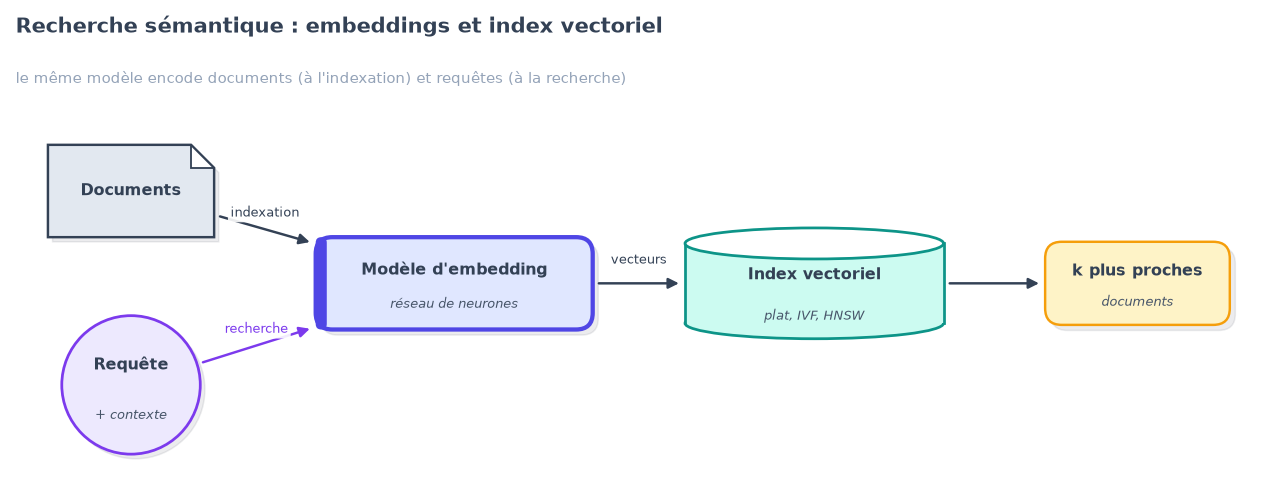

In [3]:
d = Diagram(13.5, 4.0, title="Recherche sémantique : embeddings et index vectoriel",
            subtitle="le même modèle encode documents (à l'indexation) et requêtes (à la recherche)")
d.box("docs", 1.3, 3.0, "Documents", kind="doc", color=SLATE, w=1.8, h=1.0)
d.box("q", 1.3, 0.9, "Requête", sub="+ contexte", kind="user", color=VIOLET, w=1.5)
d.box("emb", 4.8, 2.0, "Modèle d'embedding", sub="réseau de neurones", kind="model", color=INDIGO, w=3.0, h=1.0)
d.box("idx", 8.7, 2.0, "Index vectoriel", sub="plat, IVF, HNSW", kind="db", color=TEAL, w=2.8, h=1.2)
d.box("res", 12.2, 2.0, "k plus proches", sub="documents", color=AMBER, w=2.0)
d.arrow("docs", "emb", "indexation", color=SLATE)
d.arrow("q", "emb", "recherche", color=VIOLET)
d.arrow("emb", "idx", "vecteurs", label_offset=(0, 0.25))
d.arrow("idx", "res")
d.show()

> **À retenir.** Un embedding place un document dans un espace où la proximité
> géométrique reflète la proximité de sens. La recherche sémantique devient une
> recherche des **plus proches voisins** de la requête.

## 2. Mesurer la proximité : cosinus et distance euclidienne (section *Vector Embeddings*)

Deux mesures dominent :

- la **similarité cosinus** $\cos(a, b) = \dfrac{a \cdot b}{\lVert a\rVert\,\lVert b\rVert}$,
  le cosinus de l'angle entre les deux vecteurs ;
- la **distance euclidienne** $\lVert a - b\rVert$, la longueur du segment entre les
  deux points.

**Lien entre les deux.** Si les vecteurs sont **normalisés** ($\lVert a\rVert = \lVert
b\rVert = 1$), alors
$\lVert a - b\rVert^2 = \lVert a\rVert^2 + \lVert b\rVert^2 - 2\,a\cdot b = 2\,(1 - \cos(a, b))$ :
les deux mesures classent les voisins **dans le même ordre**, et le cosinus se réduit à
un produit scalaire. C'est pourquoi on normalise presque toujours les embeddings
(`V.normalize`). Vérifions sur notre nuage synthétique : 5 000 « documents » en 32
dimensions, répartis en 20 thèmes (`V.make_embeddings`).

cos = -0.0564 ; ||a - b||^2 = 2.1128 ; 2(1 - cos) = 2.1128


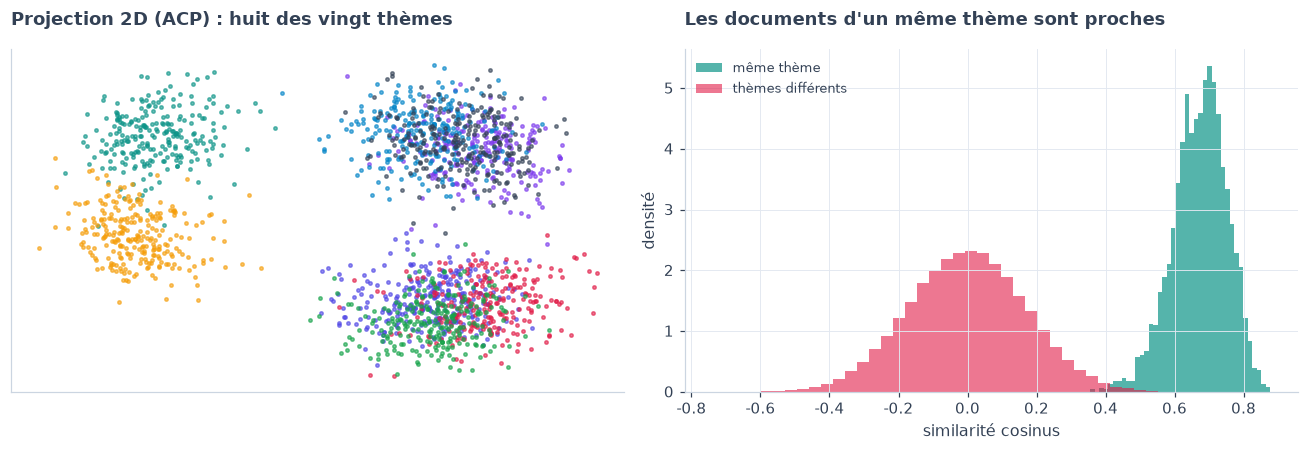

In [4]:
X, theme = V.make_embeddings(5_000, dim=32, n_topics=20, seed=0)
Q = V.make_queries(X, 200, seed=1)
i, j = 10, 3456
cos = float(X[i] @ X[j])
print(f"cos = {cos:.4f} ; ||a - b||^2 = {np.sum((X[i] - X[j]) ** 2):.4f} ; 2(1 - cos) = {2 * (1 - cos):.4f}")
# projection 2D (ACP) pour visualiser les thèmes
Xc = X - X.mean(axis=0)
_, _, Vt = np.linalg.svd(Xc[:2000], full_matrices=False)
P2 = Xc @ Vt[:2].T
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
for t_, c_ in zip(range(8), COLORS):
    m_ = theme == t_
    ax.scatter(P2[m_, 0], P2[m_, 1], color=c_, s=5, alpha=0.6)
ax.set_title("Projection 2D (ACP) : huit des vingt thèmes")
ax.set_xticks([]); ax.set_yticks([])
ax = axes[1]
meme = X[:400] @ X[:400].T
mask = theme[:400, None] == theme[None, :400]
iu = np.triu_indices(400, 1)
ax.hist(meme[iu][mask[iu]], bins=40, color=TEAL, alpha=0.7, density=True, label="même thème")
ax.hist(meme[iu][~mask[iu]], bins=40, color=ROSE, alpha=0.6, density=True, label="thèmes différents")
ax.set_xlabel("similarité cosinus"); ax.set_ylabel("densité")
ax.set_title("Les documents d'un même thème sont proches")
ax.legend(fontsize=8.5)
finish(fig)
plt.show()

> **À retenir.** Sur des vecteurs normalisés, distance euclidienne et cosinus sont
> équivalents pour classer des voisins : $\lVert a-b\rVert^2 = 2(1-\cos)$.

## 3. L'index plat (section *Vector Embeddings*, *Flat indexes*)

Le plus simple : stocker les vecteurs tels quels et comparer la requête à **tous**.
Résultat **exact**, coût **linéaire** : $n$ produits scalaires de dimension $d$ par
requête. Il sert de référence (la « vérité ») pour mesurer le **rappel** des index
approchés : la fraction des $k$ vrais plus proches voisins effectivement renvoyés.

In [5]:
flat = V.FlatIndex(X)
t0 = time.perf_counter()
verite = [flat.search(q, 10) for q in Q]
t_flat = (time.perf_counter() - t0) / len(Q)
print(f"index plat : {flat.distance_computations // len(Q)} distances par requête, {t_flat * 1e3:.2f} ms par requête")
n_docs = np.array([1e6, 1e7, 1e8, 1e9])
pd.DataFrame({"mémoire (Go), d = 1024, float32": n_docs * 1024 * 4 / 1e9,
              "temps par requête à 50 Go/s de bande passante (ms)": n_docs * 1024 * 4 / 50e9 * 1e3},
             index=[f"{int(n):,} documents".replace(",", " ") for n in n_docs]).round(1)

index plat : 5000 distances par requête, 0.02 ms par requête


,"mémoire (Go), d = 1024, float32",temps par requête à 50 Go/s de bande passante (ms)
1 000 000 documents,4.1,81.9
10 000 000 documents,41.0,819.2
100 000 000 documents,409.6,8192.0
1 000 000 000 documents,4096.0,81920.0


Le tableau donne l'ordre de grandeur pour de vrais embeddings (1 024 dimensions en
`float32`) : à cent millions de documents, il faut 400 Go de vecteurs et chaque requête
doit tous les relire, soit environ 8 secondes même au débit maximal de la mémoire.
D'où les index **approchés**, qui sacrifient un peu de rappel.

> **À retenir.** L'index plat est exact mais coûte $O(n\,d)$ par requête ; il sert de
> référence pour mesurer le rappel des index approchés.